# Vẽ cực tiểu toàn cục và cực tiểu địa phương (mục 5.1.1): f(x) = x^4 - 3x^2 + x

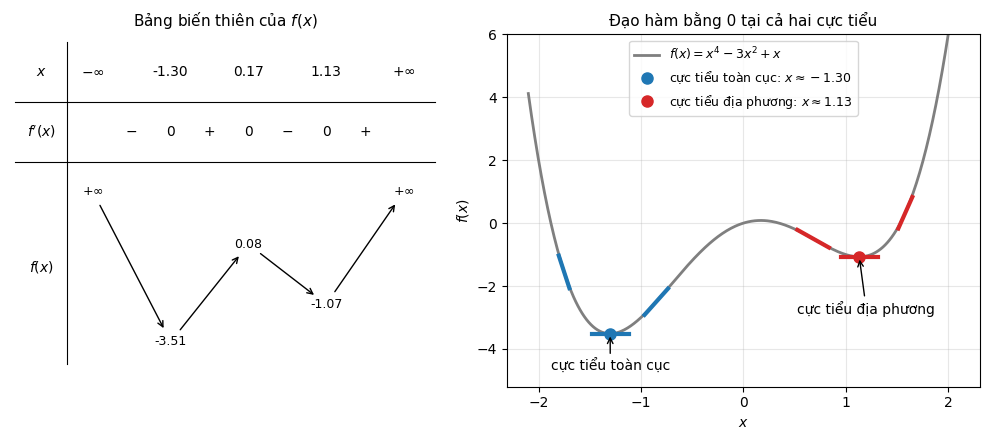

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)

def f(x):
    return x**4 - 3 * x**2 + x

def grad(x):
    """Đạo hàm f'(x)."""
    return 4 * x**3 - 6 * x + 1

# Nghiệm của f'(x) = 0, sắp tăng dần: cực tiểu toàn cục, cực đại, cực tiểu địa phương
x_global, x_max, x_local = np.sort(np.roots([4, 0, -6, 1]).real)

fig, (ax_table, ax) = plt.subplots(1, 2, figsize=(10, 4.5), width_ratios=[1, 1.1])

# Bảng biến thiên của f(x)
columns = [1.0, 2.5, 4.0, 5.5, 7.0]   # hoành độ các cột của bảng
x_labels = [r"$-\infty$", f"{x_global:.2f}", f"{x_max:.2f}", f"{x_local:.2f}", r"$+\infty$"]
f_labels = [r"$+\infty$", f"{f(x_global):.2f}", f"{f(x_max):.2f}", f"{f(x_local):.2f}", r"$+\infty$"]
f_heights = [2.3, 0.3, 1.6, 0.8, 2.3]   # vị trí giá trị f trên dòng biến thiên
for col, x_label in zip(columns, x_labels):
    ax_table.text(col, 3.9, x_label, ha="center", va="center")
for col, sign in zip([1.75, 3.25, 4.75, 6.25], ["−", "+", "−", "+"]):
    ax_table.text(col, 3.1, sign, ha="center", va="center")
for col in columns[1:-1]:
    ax_table.text(col, 3.1, "0", ha="center", va="center")
for col, height, f_label in zip(columns, f_heights, f_labels):
    ax_table.text(col, height, f_label, ha="center", va="center", fontsize=9,
                  bbox=dict(fc="white", ec="none", pad=1.5))
for i in range(4):
    ax_table.annotate("", (columns[i + 1], f_heights[i + 1]), (columns[i], f_heights[i]),
                      arrowprops=dict(arrowstyle="->", shrinkA=11, shrinkB=11))
for row, label in [(3.9, "$x$"), (3.1, "$f'(x)$"), (1.3, "$f(x)$")]:
    ax_table.text(0, row, label, ha="center", va="center")
ax_table.plot([-0.5, 7.6], [3.5, 3.5], color="black", lw=0.8)
ax_table.plot([-0.5, 7.6], [2.7, 2.7], color="black", lw=0.8)
ax_table.plot([0.5, 0.5], [0, 4.3], color="black", lw=0.8)
ax_table.set_xlim(-0.6, 7.7); ax_table.set_ylim(-0.3, 4.4)
ax_table.axis("off")
ax_table.set_title("Bảng biến thiên của $f(x)$", fontsize=11)

# Đồ thị hàm số với các đoạn tiếp tuyến: hệ số góc bằng đạo hàm tại điểm tiếp xúc
x_line = np.linspace(-2.1, 2.1, 400)
ax.plot(x_line, f(x_line), color="#7F7F7F", lw=2, label=r"$f(x) = x^4 - 3x^2 + x$")
for x_min, color, name in [(x_global, "#1F77B4", "cực tiểu toàn cục"),
                           (x_local, "#D62728", "cực tiểu địa phương")]:
    for x_point in [x_min - 0.45, x_min, x_min + 0.45]:
        half_width = 0.18 / np.sqrt(1 + grad(x_point)**2 / 9)   # giữ độ dài đoạn gần đều
        x_tangent = np.array([x_point - half_width, x_point + half_width])
        ax.plot(x_tangent, f(x_point) + grad(x_point) * (x_tangent - x_point), color=color, lw=3)
    ax.plot(x_min, f(x_min), "o", color=color, ms=8, label=rf"{name}: $x \approx {x_min:.2f}$")
ax.annotate("cực tiểu toàn cục", (x_global, f(x_global)), (-1.3, -4.7), ha="center",
            arrowprops=dict(arrowstyle="->"))
ax.annotate("cực tiểu địa phương", (x_local, f(x_local)), (1.2, -2.9), ha="center",
            arrowprops=dict(arrowstyle="->"))
ax.set_ylim(-5.2, 6)
ax.set_xlabel("$x$"); ax.set_ylabel("$f(x)$")
ax.set_title("Đạo hàm bằng 0 tại cả hai cực tiểu", fontsize=11)
ax.legend(loc="upper center", fontsize=9); ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(IMAGES / "global_local_minima.png", dpi=150)